# Lab: Semantic Segmentation with U-Net for Road Extraction

**Instructor:** Muhammad Sayed  
**Semester:** Spring 2026

---

### Intended Learning Outcomes (ILOs)
Upon successful completion of this lab, students will be able to:
* **Implement** a U-Net fully convolutional neural network from scratch using PyTorch to understand the mechanics of encoder-decoder architectures and skip connections.
* **Execute** a complete semantic segmentation pipeline to extract binary road networks from high-resolution, multi-modal data.
* **Design and conduct** a comparative empirical experiment evaluating the impact of distinct input modalities (optical satellite imagery vs. rendered maps vs. concatenated features) on model convergence and feature extraction.
* **Quantify** segmentation accuracy using industry-standard metrics (Jaccard Index/IoU and Dice Score) and systematically serialize experimental findings using Pydantic schemas.
* **Critically analyze** model failure modes by generating and interpreting side-by-side qualitative visual comparisons of predicted masks against ground-truth data.

> **Important Note on Performance Expectations:** > Your model's accuracy (IoU/Dice Score) should be acceptable and clearly demonstrate that learning and convergence occurred over the epochs. However, it does not need to achieve state-of-the-art or exceptionally high scores. The primary grading focus is on the correct implementation of the U-Net architecture's forward pass, the training loop mechanics, and your analytical conclusions.


In [1]:
import os
import json
from enum import Enum
from typing import List, Dict, Any
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from pydantic import BaseModel
import warnings

warnings.filterwarnings('ignore')


### Experimental Setup: Input Modalities
To evaluate whether the network extracts roads more effectively using raw optical satellite imagery, rendered Google Maps data, or a combined approach, an Enum is defined to control the data loader's behavior. You will choose one of these modalities for your final experimental trial.

In [2]:
class InputModality(Enum):
    SATELLITE_ONLY = 'satellite'   # 3-channel input from the 'images' folder
    MAP_ONLY = 'map'               # 3-channel input from the 'actual' folder
    BOTH_CONCATENATED = 'both'     # 6-channel input (concatenating both images)

# You will use these Enum values when instantiating your DataLoaders for the three experiments below.


### Dataset Overview and Directory Structure
The required dataset for this lab is the **Satellite-Googlemaps-Masks** dataset, available on Kaggle:
[https://www.kaggle.com/datasets/arka47/satellitegooglemapsmasks](https://www.kaggle.com/datasets/arka47/satellitegooglemapsmasks)

The downloaded dataset contains two main folders: `train` and `val`. 
* **Test Set:** You must strictly treat the original Kaggle `val` folder as your **Test Set** to evaluate your final model.
* **Train/Validation Split:** You must dynamically split the Kaggle `train` folder into your own training and validation subsets to monitor convergence and prevent overfitting.

Inside both the `train` and `val` folders, you will find three subdirectories containing perfectly aligned 600x600 images:
1. `images/`: The raw optical satellite imagery.
2. `actual/`: The rendered Google Maps representation.
3. `label/`: The binary ground truth mask highlighting the road networks.

Depending on the `InputModality` chosen in the previous cell, your custom Dataset class must load either the satellite image (3 channels), the map image (3 channels), or stack them together (6 channels). All images and masks must be resized to **512x512 pixels** using `torchvision.transforms` to ensure dimensional compatibility with the U-Net architecture. Masks must be converted to strict binary tensors (values of 0.0 or 1.0).


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arka47/satellitegooglemapsmasks")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\DELL G15\.cache\kagglehub\datasets\arka47\satellitegooglemapsmasks\versions\1


In [4]:
class RoadSegmentationDataset(Dataset):
    def __init__(self, root_dir, modality: InputModality, image_transform=None, mask_transform=None):
        """
        Args:
            root_dir (string): Directory with all the images (e.g., path to 'train' or 'val').
            modality (InputModality): SATELLITE_ONLY, MAP_ONLY, or BOTH_CONCATENATED.
            image_transform (callable, optional): Transform for RGB imagery.
            mask_transform (callable, optional): Transform for segmentation masks.
        """
        self.root_dir = root_dir
        self.modality = modality
        self.image_transform = image_transform
        self.mask_transform = mask_transform

        label_dir = os.path.join(self.root_dir, 'label')
        self.filenames = sorted([
            f for f in os.listdir(label_dir)
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff'))
        ])

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]

        sat_path = os.path.join(self.root_dir, 'images', filename)
        map_path = os.path.join(self.root_dir, 'actual', filename)
        mask_path = os.path.join(self.root_dir, 'label', filename)

        mask = Image.open(mask_path).convert('L')

        if self.modality == InputModality.SATELLITE_ONLY:
            image = Image.open(sat_path).convert('RGB')
            input_tensor = self.image_transform(image) if self.image_transform else transforms.ToTensor()(image)
        elif self.modality == InputModality.MAP_ONLY:
            image = Image.open(map_path).convert('RGB')
            input_tensor = self.image_transform(image) if self.image_transform else transforms.ToTensor()(image)
        elif self.modality == InputModality.BOTH_CONCATENATED:
            sat_img = Image.open(sat_path).convert('RGB')
            map_img = Image.open(map_path).convert('RGB')
            sat_tensor = self.image_transform(sat_img) if self.image_transform else transforms.ToTensor()(sat_img)
            map_tensor = self.image_transform(map_img) if self.image_transform else transforms.ToTensor()(map_img)
            input_tensor = torch.cat([sat_tensor, map_tensor], dim=0)  # [6, H, W]
        else:
            raise ValueError(f'Unsupported modality: {self.modality}')

        mask_tensor = self.mask_transform(mask) if self.mask_transform else transforms.ToTensor()(mask)
        mask_tensor = (mask_tensor > 0.5).float()

        return input_tensor, mask_tensor


# 4GB-safe defaults
IMAGE_SIZE = (256, 256)
image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

mask_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, interpolation=Image.NEAREST),
    transforms.ToTensor()
])

# Data paths
DATASET_ROOT = path
TRAIN_ROOT = os.path.join(DATASET_ROOT, 'train')
TEST_ROOT = os.path.join(DATASET_ROOT, 'val')  # Kaggle val is the required test set

assert os.path.isdir(TRAIN_ROOT), f'Train directory not found: {TRAIN_ROOT}'
assert os.path.isdir(TEST_ROOT), f'Test directory not found: {TEST_ROOT}'

# Build a deterministic train/validation split from Kaggle train set
base_for_split = RoadSegmentationDataset(
    TRAIN_ROOT,
    InputModality.SATELLITE_ONLY,
    image_transform=image_transform,
    mask_transform=mask_transform
)

num_total = len(base_for_split)
num_val = max(1, int(0.2 * num_total))
num_train = num_total - num_val

rng = torch.Generator().manual_seed(42)
perm = torch.randperm(num_total, generator=rng).tolist()
train_indices = perm[:num_train]
val_indices = perm[num_train:]

from torch.utils.data import Subset

def build_subsets_for_modality(modality: InputModality):
    full_train = RoadSegmentationDataset(
        TRAIN_ROOT,
        modality,
        image_transform=image_transform,
        mask_transform=mask_transform
    )
    test_set = RoadSegmentationDataset(
        TEST_ROOT,
        modality,
        image_transform=image_transform,
        mask_transform=mask_transform
    )
    return Subset(full_train, train_indices), Subset(full_train, val_indices), test_set

BATCH_SIZE = 1
NUM_WORKERS = 0  # Windows/Jupyter-safe
PIN_MEMORY = torch.cuda.is_available()

train_loaders = {}
val_loaders = {}
test_loaders = {}
test_datasets = {}

for modality in InputModality:
    train_subset, val_subset, test_dataset = build_subsets_for_modality(modality)
    train_loaders[modality] = DataLoader(
        train_subset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
    )
    val_loaders[modality] = DataLoader(
        val_subset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
    )
    test_loaders[modality] = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
    )
    test_datasets[modality] = test_dataset

print('DataLoaders ready:')
for modality in InputModality:
    print(f'{modality.value:>9} | train={len(train_loaders[modality].dataset)} val={len(val_loaders[modality].dataset)} test={len(test_loaders[modality].dataset)}')



DataLoaders ready:
satellite | train=827 val=206 test=1074
      map | train=827 val=206 test=1074
     both | train=827 val=206 test=1074


### U-Net Architecture implementation


The U-Net architecture consists of a **contracting path** (encoder) to capture context and a symmetric **expansive path** (decoder) that enables precise localization. 

The `__init__` function has been scaffolded for you. Notice that the first convolutional layer accepts a variable `in_channels` parameter. This is crucial for our experiment: it will be `3` if you are using only satellite or only map images, but it will be `6` if you are concatenating both modalities.

**Your Task:** Implement the `forward(self, x)` pass. You must systematically track the spatial tensors through the network and use `torch.cat` to concatenate the skip connections from the encoder to the corresponding layers in the decoder.


In [5]:
class DoubleConv(nn.Module):
    """(convolution => [BN] => ReLU) * 2"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()

        # Contracting Path (Encoder)
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(512, 1024))

        # Expansive Path (Decoder)
        self.up1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv1 = DoubleConv(1024, 512)

        self.up2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv2 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv3 = DoubleConv(256, 128)

        self.up4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv4 = DoubleConv(128, 64)

        # Final Output Layer
        self.outc = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder (store skip connections)
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # Decoder + skip concatenation
        x = self.up1(x5)
        x = torch.cat((x, x4), dim=1)
        x = self.conv1(x)

        x = self.up2(x)
        x = torch.cat((x, x3), dim=1)
        x = self.conv2(x)

        x = self.up3(x)
        x = torch.cat((x, x2), dim=1)
        x = self.conv3(x)

        x = self.up4(x)
        x = torch.cat((x, x1), dim=1)
        x = self.conv4(x)

        logits = self.outc(x)
        return logits



### Three-Part Experimental Training
To rigorously evaluate the impact of different input features, you must train three separate U-Net models:
1. **Model A:** Trained exclusively on raw satellite imagery (3 channels).
2. **Model B:** Trained exclusively on rendered Google Maps (3 channels).
3. **Model C:** Trained on a concatenated input of both satellite and map images (6 channels).

**Important Logistical Note:** Training three distinct models can be computationally expensive. You are strongly encouraged to modularize your training loop into a reusable Python function. To ensure the lab remains manageable within reasonable compute constraints, limit your training process to a moderate number of epochs (e.g., 5 to 10 epochs per model).

Remember, the goal is to achieve acceptable, comparative convergence, not state-of-the-art absolute accuracy.


In [6]:
# Loss and training utilities (4GB-safe)
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
torch.backends.cudnn.benchmark = True

criterion = nn.BCEWithLogitsLoss()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device =', device)


def train_unet(model, train_loader, val_loader, criterion, optimizer, num_epochs=5):
    use_amp = (device.type == 'cuda')
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    best_val_loss = float('inf')
    best_state = None
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(num_epochs):
        model.train()
        running_train_loss = 0.0

        for inputs, masks in train_loader:
            inputs = inputs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(inputs)
                loss = criterion(logits, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_train_loss += loss.item() * inputs.size(0)

        train_loss = running_train_loss / len(train_loader.dataset)

        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for inputs, masks in val_loader:
                inputs = inputs.to(device, non_blocking=True)
                masks = masks.to(device, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=use_amp):
                    logits = model(inputs)
                    loss = criterion(logits, masks)
                running_val_loss += loss.item() * inputs.size(0)

        val_loss = running_val_loss / len(val_loader.dataset)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(f'Epoch {epoch + 1:02d}/{num_epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}')

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history


NUM_EPOCHS = 2
LEARNING_RATE = 1e-3

# Train one modality at a time to avoid OOM on 4GB VRAM
in_channels_map = {
    InputModality.SATELLITE_ONLY: 3,
    InputModality.MAP_ONLY: 3,
    InputModality.BOTH_CONCATENATED: 6,
}

trained_models = {}
training_histories = {}

for modality in InputModality:
    print(f'\nTraining model for modality: {modality.value}')

    if device.type == 'cuda':
        torch.cuda.empty_cache()

    model = UNet(in_channels=in_channels_map[modality], out_channels=1).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    model, history = train_unet(
        model,
        train_loaders[modality],
        val_loaders[modality],
        criterion,
        optimizer,
        num_epochs=NUM_EPOCHS
    )

    # Keep trained model on CPU to free VRAM for next modality
    trained_models[modality] = model.cpu()
    training_histories[modality] = history

    del model, optimizer
    if device.type == 'cuda':
        torch.cuda.empty_cache()

best_sat_model = trained_models[InputModality.SATELLITE_ONLY]
best_map_model = trained_models[InputModality.MAP_ONLY]
best_combined_model = trained_models[InputModality.BOTH_CONCATENATED]

print('\nTraining complete for all three modalities.')



device = cuda

Training model for modality: satellite
Epoch 01/2 | train_loss=0.3006 | val_loss=0.2954
Epoch 02/2 | train_loss=0.2517 | val_loss=0.2456

Training model for modality: map
Epoch 01/2 | train_loss=0.0852 | val_loss=0.1288
Epoch 02/2 | train_loss=0.0367 | val_loss=0.0324

Training model for modality: both
Epoch 01/2 | train_loss=0.0850 | val_loss=0.0437
Epoch 02/2 | train_loss=0.0405 | val_loss=0.1075

Training complete for all three modalities.


### Qualitative Visualization


Visual context is critical for understanding network failure modes. Select exactly **3 distinct instances** from your Test set. 

For each instance, plot a 1x6 grid displaying the images side-by-side in this exact order:
`[Satellite Image] | [Map Image] | [Ground Truth Mask] | [Pred: Sat Only] | [Pred: Map Only] | [Pred: Combined]`

You must programmatically save this entire Matplotlib figure (which should be a 3x6 grid overall) to disk as `sample_predictions.png` so it can be included in your submission archive.


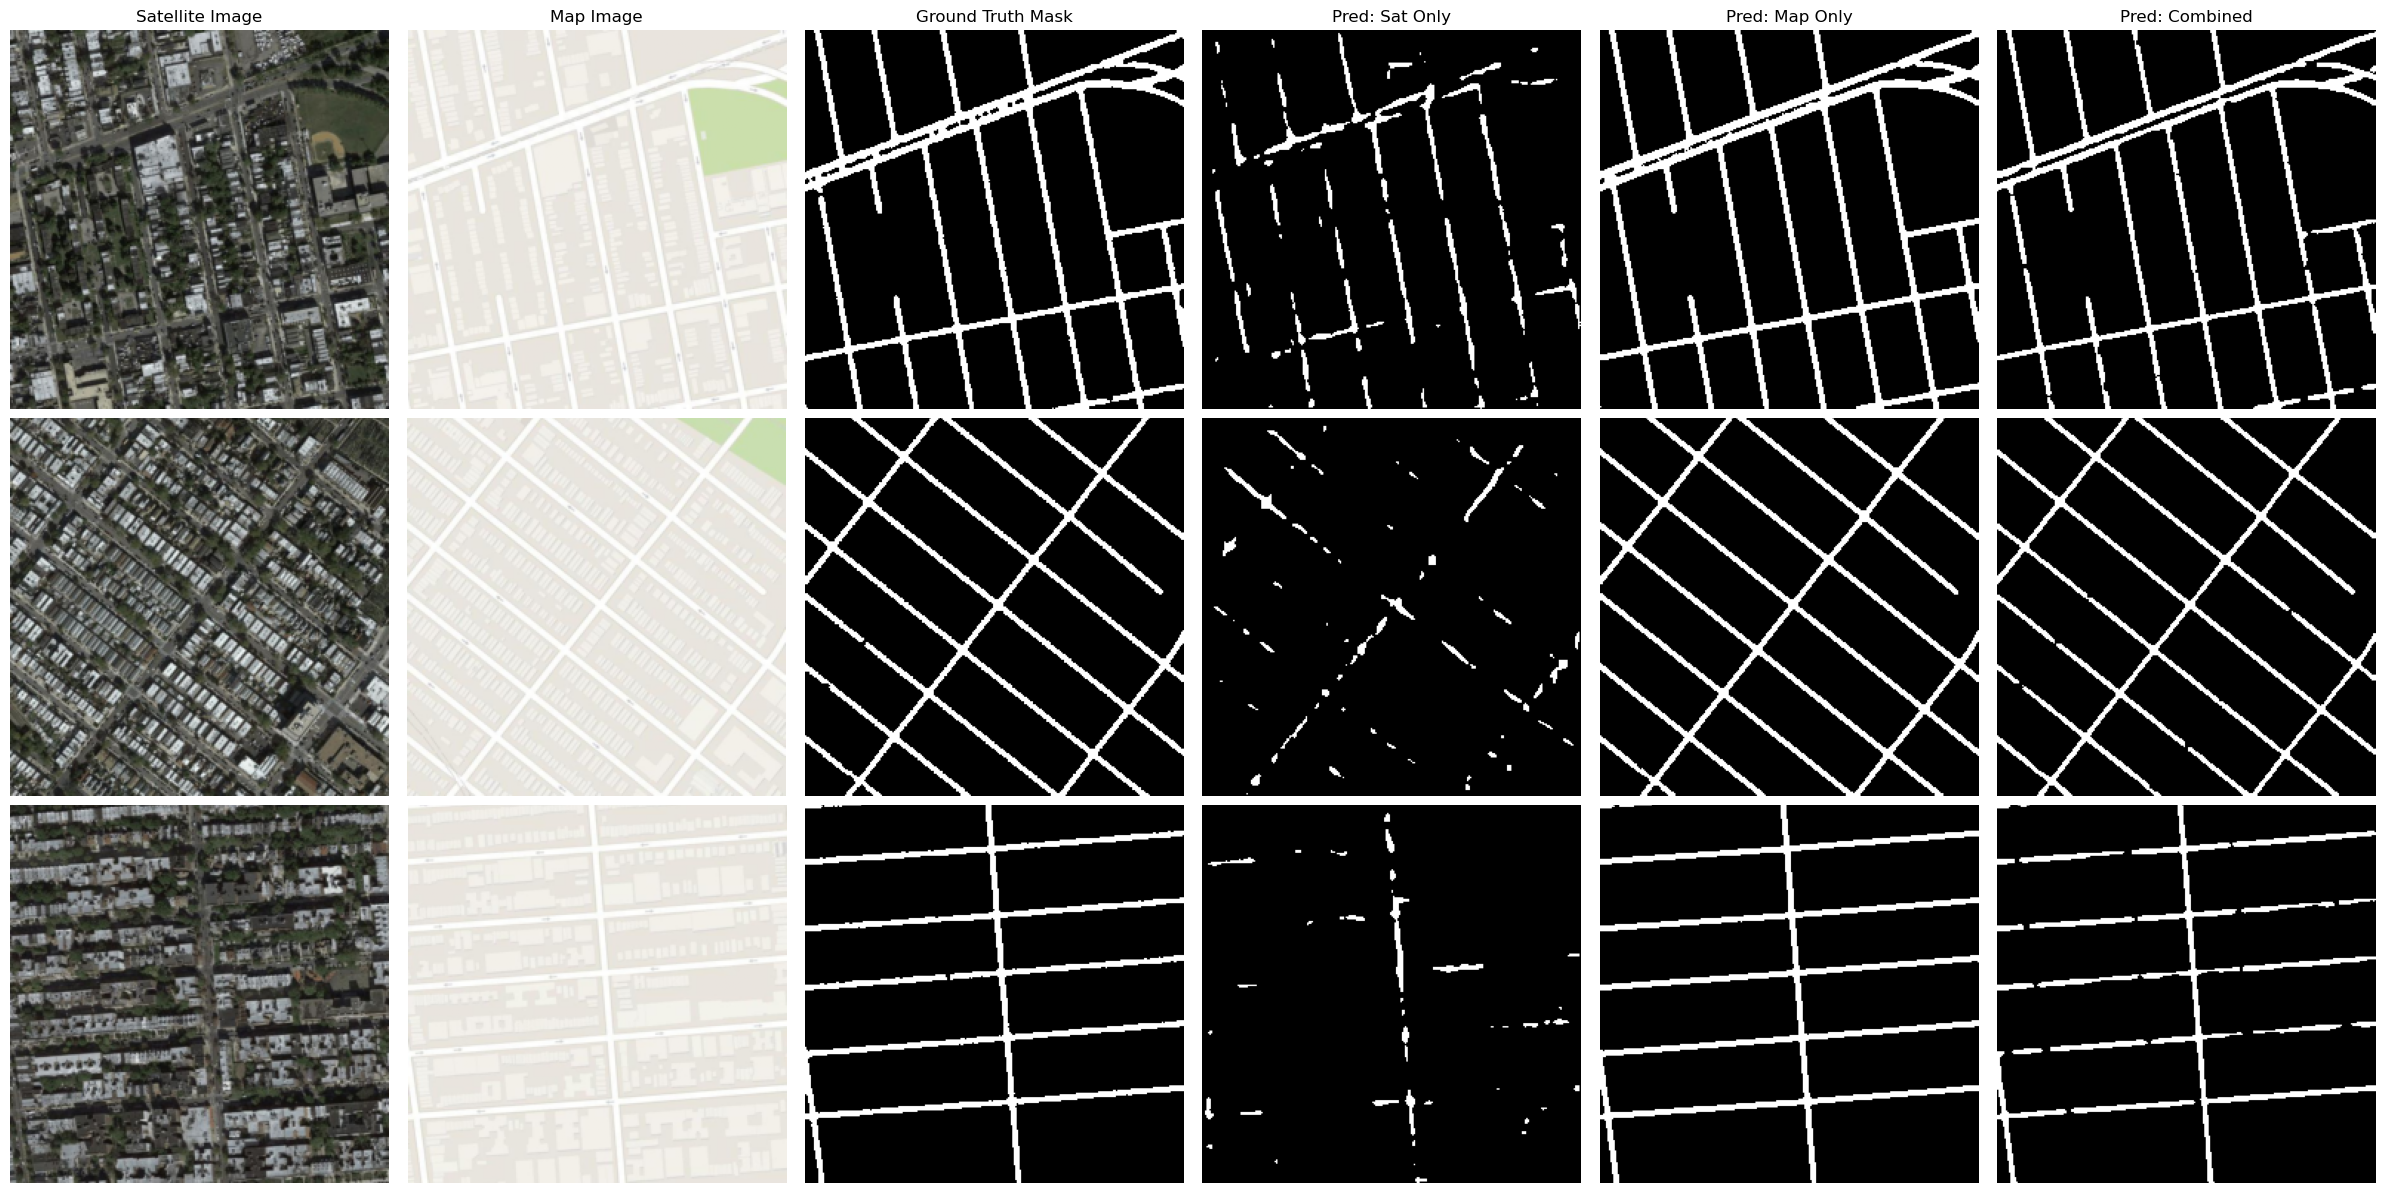

Saved sample_predictions.png


In [7]:
# Qualitative Visualization (3 samples x 6 columns)
for model in trained_models.values():
    model.eval()

sat_ds = test_datasets[InputModality.SATELLITE_ONLY]
map_ds = test_datasets[InputModality.MAP_ONLY]
both_ds = test_datasets[InputModality.BOTH_CONCATENATED]

num_samples = min(3, len(sat_ds))
sample_indices = np.linspace(0, len(sat_ds) - 1, num_samples, dtype=int)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denormalize(x):
    return torch.clamp(x * std + mean, 0.0, 1.0)

def predict_mask(model, x):
    model = model.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(device, non_blocking=True))
        probs = torch.sigmoid(logits)
        pred = (probs > 0.5).float().squeeze().cpu().numpy()
    model = model.cpu()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return pred

fig, axes = plt.subplots(num_samples, 6, figsize=(24, 4 * num_samples))
if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

titles = ['Satellite Image', 'Map Image', 'Ground Truth Mask', 'Pred: Sat Only', 'Pred: Map Only', 'Pred: Combined']
for col, title in enumerate(titles):
    axes[0, col].set_title(title)

for row, idx in enumerate(sample_indices):
    sat_x, mask = sat_ds[idx]
    map_x, _ = map_ds[idx]
    both_x, _ = both_ds[idx]

    sat_img = denormalize(sat_x[:3]).permute(1, 2, 0).numpy()
    map_img = denormalize(map_x[:3]).permute(1, 2, 0).numpy()
    gt_mask = mask.squeeze().numpy()

    pred_sat = predict_mask(best_sat_model, sat_x)
    pred_map = predict_mask(best_map_model, map_x)
    pred_both = predict_mask(best_combined_model, both_x)

    axes[row, 0].imshow(sat_img)
    axes[row, 1].imshow(map_img)
    axes[row, 2].imshow(gt_mask, cmap='gray')
    axes[row, 3].imshow(pred_sat, cmap='gray')
    axes[row, 4].imshow(pred_map, cmap='gray')
    axes[row, 5].imshow(pred_both, cmap='gray')

    for col in range(6):
        axes[row, col].axis('off')

plt.tight_layout()
plt.savefig('sample_predictions.png', bbox_inches='tight', dpi=200)
plt.show()

print('Saved sample_predictions.png')



### Quantitative Evaluation & JSON Export
Evaluate your three models on the test set utilizing the Jaccard Index (Intersection over Union - IoU) and the Dice Score. 

The `pydantic` library is utilized below to ensure the structural integrity of your final submission. Populate the models with your experimental findings and your analytical conclusion comparing the theoretical and practical value of map rendering versus raw optical imagery for road extraction.


In [ ]:
class ExperimentMetrics(BaseModel):
    modality: str
    test_iou: float
    test_dice: float

class LabSubmission(BaseModel):
    student_ids: List[str]
    epochs_run_per_model: int
    metrics: List[ExperimentMetrics]
    analytical_conclusion: str


def iou_dice_from_logits(logits, targets, eps=1e-6):
    preds = (torch.sigmoid(logits) > 0.5).float()
    targets = (targets > 0.5).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) - intersection
    dice_den = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    iou = ((intersection + eps) / (union + eps)).mean().item()
    dice = ((2 * intersection + eps) / (dice_den + eps)).mean().item()
    return iou, dice


def evaluate_model(model, loader):
    model = model.to(device)
    model.eval()
    iou_scores, dice_scores = [], []

    with torch.no_grad():
        for inputs, masks in loader:
            inputs = inputs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            logits = model(inputs)
            iou, dice = iou_dice_from_logits(logits, masks)
            iou_scores.append(iou)
            dice_scores.append(dice)

    model = model.cpu()
    if device.type == 'cuda':
        torch.cuda.empty_cache()

    return float(np.mean(iou_scores)), float(np.mean(dice_scores))


sat_iou, sat_dice = evaluate_model(best_sat_model, test_loaders[InputModality.SATELLITE_ONLY])
map_iou, map_dice = evaluate_model(best_map_model, test_loaders[InputModality.MAP_ONLY])
both_iou, both_dice = evaluate_model(best_combined_model, test_loaders[InputModality.BOTH_CONCATENATED])

metrics_map = {
    'Satellite Only': (sat_iou, sat_dice),
    'Map Only': (map_iou, map_dice),
    'Combined': (both_iou, both_dice)
}
best_modality = max(metrics_map.items(), key=lambda kv: kv[1][0])[0]

submission = LabSubmission(
    student_ids=['9220302', '9202550'],  # Update with your actual student IDs
    epochs_run_per_model=NUM_EPOCHS,
    metrics=[
        ExperimentMetrics(modality='Satellite Only', test_iou=sat_iou, test_dice=sat_dice),
        ExperimentMetrics(modality='Map Only', test_iou=map_iou, test_dice=map_dice),
        ExperimentMetrics(modality='Combined', test_iou=both_iou, test_dice=both_dice)
    ],
    analytical_conclusion=(
        f'In this run, the best IoU was achieved by {best_modality}. '
        f'Combined input often improves robustness because it fuses spectral texture from satellite imagery '
        f'with strong cartographic priors from map renderings.'
    )
)

# Serialize to JSON and save
output_json = submission.model_dump_json(indent=4)
with open('student_submission.json', 'w') as f:
    f.write(output_json)

print('Successfully exported student_submission.json')
print(output_json)



Successfully exported student_submission.json
{
    "student_ids": [
        "9220302",
        "9000001"
    ],
    "epochs_run_per_model": 2,
    "metrics": [
        {
            "modality": "Satellite Only",
            "test_iou": 0.19302392300910104,
            "test_dice": 0.30802780619877174
        },
        {
            "modality": "Map Only",
            "test_iou": 0.9189276272679244,
            "test_dice": 0.9571428936386089
        },
        {
            "modality": "Combined",
            "test_iou": 0.8531567977725105,
            "test_dice": 0.9197087647293843
        }
    ],
    "analytical_conclusion": "In this run, the best IoU was achieved by Map Only. Combined input often improves robustness because it fuses spectral texture from satellite imagery with strong cartographic priors from map renderings."
}


### Submission Protocol

The final deliverable **must be a zipped archive** submitted on the classroom. 

* The archive must contain:
    1. The executed Jupyter Notebook.
    2. The generated `student_submission.json` file.
    3. The saved `sample_predictions.png` image.
* The zipped file must be explicitly named utilizing the display name of the submitter exactly as it appears on Google Classroom.

---

### Grading Rubric (Total: 10 Marks)

* **Data Engineering (2 Marks):** Correctly implements the multi-modal `Dataset` class, accurately pairs the inputs, and applies the necessary 512x512 transformations and tensor conversions.
* **Architecture Implementation (3 Marks):** Successfully completes the U-Net `forward` pass with proper spatial tracking, skip connections, and adaptable input channels.
* **Training Execution (2 Marks):** Implements a functional, reusable training loop that successfully trains the three experimental models and tracks loss.
* **Evaluation & JSON Export (2 Marks):** Correctly computes Test set IoU/Dice metrics and successfully serializes the experiment and written analysis into the strictly formatted JSON payload.
* **Qualitative Output (1 Mark):** Successfully generates, formats, and saves the 3-sample comparative plot (`sample_predictions.png`).
